# Assignment 2 — The Bookstore Intelligence Mission
### Complete Colab version (same simple structure as your uploaded notebook)
Run the cells **from top to bottom**. This notebook scrapes the actual catalogue, solves the CEO challenge, and creates the CSV, Excel workbook, chart, written answers and a ZIP for GitHub.
In the code below, change `PAGE_LIMIT = None` to `PAGE_LIMIT = 3` for the minimum assignment or `5` for the bonus. `None` completes the Boss Level.


In [4]:
!pip -q install requests beautifulsoup4 pandas numpy matplotlib xlsxwriter tabulate



## Step 1: Save the working Python code
This cell creates a real `bookstore_scraper.py` file so you can upload the **same code** to GitHub. Edit `PAGE_LIMIT` and optionally `GITHUB_URL` near the top.


In [5]:
%%writefile bookstore_scraper.py
"""Assignment 2: The Bookstore Intelligence Mission.

Website: https://books.toscrape.com/ (practice sandbox)
"""

import time
import zipfile
from pathlib import Path
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup


BASE_URL = "https://books.toscrape.com/"
PAGE_LIMIT = None
BUDGET_GBP = 100
GITHUB_URL = ""     # Optional: paste https://github.com/YOURNAME/bookstore-intelligence here
DELAY_SECONDS = 0.15
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def extract_books(html, page_url):  #Parse HTML page one at a time and return list of dictionaries
    soup = BeautifulSoup(html, "html.parser")
    records = []
    for card in soup.select("article.product_pod"):
        link = card.select_one("h3 a")
        rating_classes = card.select_one("p.star-rating").get("class", [])
        word = next((c for c in rating_classes if c in RATING_MAP), None)
        if not word:
            raise ValueError(f"Unknown star rating class: {rating_classes}")

        raw_price = card.select_one("p.price_color").get_text(strip=True)
        price = float(raw_price.replace("£", "").replace("Â", "").strip())
        availability = card.select_one("p.instock.availability").get_text(" ", strip=True)
        records.append({
            "Title": link.get("title", link.get_text(" ", strip=True)),
            "Price": price,
            "Rating": RATING_MAP[word],
            "Availability": availability,
            "URL": urljoin(page_url, link["href"]),
        })
    return records, bool(soup.select_one("li.next a"))


def scrape_books(max_pages=PAGE_LIMIT):

    records = []
    with requests.Session() as session:
        session.headers.update({"User-Agent": "BookstoreIntelligencePractice/1.0"})
        page_number = 1
        while max_pages is None or page_number <= max_pages:
            url = urljoin(BASE_URL, f"catalogue/page-{page_number}.html")
            response = session.get(url, timeout=25)
            response.raise_for_status()
            response.encoding = "utf-8"
            page_records, has_next = extract_books(response.text, url)
            if not page_records:
                raise RuntimeError(f"No product cards on {url}; inspect the website HTML.")
            records.extend(page_records)
            print(f"Page {page_number}: {len(page_records)} books")
            if not has_next:
                break
            page_number += 1
            time.sleep(DELAY_SECONDS)
    df = pd.DataFrame(records, columns=["Title", "Price", "Rating", "Availability", "URL"])
    df["Price"] = pd.to_numeric(df["Price"], errors="raise").round(2)
    df["Rating"] = pd.to_numeric(df["Rating"], errors="raise").astype(int)
    df["Availability"] = df["Availability"].str.strip()
    df = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)
    if df.empty or df[["Title", "Price", "Rating", "Availability", "URL"]].isna().any().any():
        raise ValueError("Incomplete dataset: check the scraping selectors.")
    if not df["Rating"].between(1, 5).all():
        raise ValueError("Unexpected rating outside 1-5.")
    return df


def best_purchase(df, budget_gbp=BUDGET_GBP):
    """Exact 0/1 knapsack: maximize stars - if tied, prefer least expense."""
    prices = (df["Price"].to_numpy() * 100).round().astype(int)
    ratings = df["Rating"].to_numpy(dtype=int)
    budget_pence = round(budget_gbp * 100)
    n = len(df)
    unreachable = -1000000
    dp = np.full((n + 1, budget_pence + 1), unreachable, dtype=np.int32)
    dp[0, 0] = 0
    for i, (cost, stars) in enumerate(zip(prices, ratings), start=1):
        dp[i, :] = dp[i - 1, :]
        if cost <= budget_pence:
            dp[i, cost:] = np.maximum(dp[i - 1, cost:], dp[i - 1, :-cost] + stars)
    maximum_stars = int(dp[n].max())
    cheapest_cost = int(np.flatnonzero(dp[n] == maximum_stars)[0])
    chosen_indexes = []
    remaining = cheapest_cost
    for i in range(n, 0, -1):
        if dp[i, remaining] != dp[i - 1, remaining]:
            chosen_indexes.append(i - 1)
            remaining -= prices[i - 1]
    picks = df.iloc[sorted(chosen_indexes)].copy().reset_index(drop=True)
    assert int(picks["Rating"].sum()) == maximum_stars
    assert int((picks["Price"] * 100).round().sum()) == cheapest_cost
    return picks, maximum_stars, cheapest_cost / 100


def analyze(df):
    """Return 7 intelligence answers, top 5, and the rating counts."""
    priciest = df.loc[df["Price"].idxmax()]
    cheapest = df.loc[df["Price"].idxmin()]
    five_star = df.loc[df["Rating"] == 5]
    top_five = df.sort_values(["Rating", "Price", "Title"], ascending=[False, True, True]).head(5).copy()
    cheapest_five = five_star.sort_values(["Price", "Title"]).iloc[0] if not five_star.empty else None
    stock_fraction = df["Availability"].str.contains("in stock", case=False, regex=False).mean() * 100
    results = [
        ("1. Most expensive book", str(priciest["Title"]), float(priciest["Price"])),
        ("2. Cheapest book", str(cheapest["Title"]), float(cheapest["Price"])),
        ("3. Average price", "GBP", round(float(df["Price"].mean()), 2)),
        ("4. Number of 5-star books", "Count", int(len(five_star))),
        ("5. Percentage in stock", "Percent", round(float(stock_fraction), 2)),
        ("6. Top 5 highest-rated", "See Top_5 sheet (price breaks rating ties)", ""),
        ("7. Cheapest 5-star book", str(cheapest_five["Title"]) if cheapest_five is not None else "None", float(cheapest_five["Price"]) if cheapest_five is not None else ""),
    ]
    counts = df["Rating"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0).sort_index()
    return results, top_five, counts


def plot_ratings(counts):
    fig, ax = plt.subplots(figsize=(8.2, 4.8))
    bars = ax.bar([str(x) for x in counts.index], counts.to_numpy(), edgecolor="black")
    ax.bar_label(bars, padding=3)
    ax.set_title("Competitor books by star rating")
    ax.set_xlabel("Star rating")
    ax.set_ylabel("Number of books")
    ax.set_ylim(0, max(int(counts.max()) * 1.16, 5))
    fig.tight_layout()
    fig.savefig("rating_counts.png", dpi=170)
    plt.show()
    plt.close(fig)


def save_excel(df, answers, top_five, counts, picks, stars, cost):
    with pd.ExcelWriter("Bookstore_Intelligence_Results.xlsx", engine="xlsxwriter") as writer:
        df.to_excel(writer, sheet_name="Books_Data", index=False)
        pd.DataFrame(answers, columns=["Question", "Answer", "Value"]).to_excel(
            writer, sheet_name="Analysis", index=False
        )
        counts_df = pd.DataFrame({"Star rating": counts.index, "Number of books": counts.values})
        counts_df.to_excel(writer, sheet_name="Rating_Counts", index=False)
        top_five.to_excel(writer, sheet_name="Top_5", index=False)
        picks[["Title", "Price", "Rating", "URL"]].to_excel(
            writer, sheet_name="CEO_Challenge", index=False, startrow=2
        )
        recon = pd.DataFrame([
            ["Book title", "h3 a", "title attribute, keeps the complete title"],
            ["Price", "p.price_color", "remove GBP symbol; convert to float"],
            ["Rating", "p.star-rating", "read One..Five from CSS class; map to 1..5"],
            ["Availability", "p.instock.availability", "strip surrounding whitespace"],
            ["Product URL", "h3 a[href]", "urljoin() produces an absolute URL"],
            ["Book card", "article.product_pod", "loop through all book cards"],
        ], columns=["Field", "HTML selector", "Notes"])
        recon.to_excel(writer, sheet_name="Reconnaissance", index=False)

        wb = writer.book
        header = wb.add_format({"bold": True, "font_color": "white", "bg_color": "#203650", "border": 0, "valign": "vcenter"})
        money = wb.add_format({"num_format": '"£"#,##0.00'})
        total = wb.add_format({"bold": True, "bg_color": "#DFEAF4", "num_format": '"£"#,##0.00'})
        total_int = wb.add_format({"bold": True, "bg_color": "#DFEAF4", "num_format": "0"})
        for name, sheet in writer.sheets.items():
            sheet.freeze_panes(1, 0)
            sheet.set_default_row(19)
            sheet.set_tab_color("#2E6287")
            sheet.set_column(0, 0, 42)
            sheet.set_column(1, 1, 20)
            sheet.set_column(2, 2, 16)
            sheet.set_column(3, 3, 20)
            sheet.set_column(4, 4, 66)
            if name != "CEO_Challenge":
                col_count = 5 if name in ("Books_Data", "Top_5") else (3 if name in ("Analysis", "Reconnaissance") else 2)
                sheet.set_row(0, 26)
                for c in range(col_count):
                    cell_name = (df.columns[c] if name == "Books_Data" else
                                 top_five.columns[c] if name == "Top_5" else
                                 ["Question", "Answer", "Value"][c] if name == "Analysis" else
                                 ["Field", "HTML selector", "Notes"][c] if name == "Reconnaissance" else
                                 ["Star rating", "Number of books"][c])
                    sheet.write(0, c, cell_name, header)
                rows = {"Books_Data": len(df), "Analysis": len(answers),
                        "Rating_Counts": 5, "Top_5": len(top_five), "Reconnaissance": 6}.get(name)
                if rows:
                    sheet.autofilter(0, 0, rows, col_count - 1)
        for sheet_name in ("Books_Data", "Top_5"):
            writer.sheets[sheet_name].set_column(1, 1, 17, money)
            writer.sheets[sheet_name].set_column(4, 4, 75)
        writer.sheets["Analysis"].set_column(0, 0, 29)
        writer.sheets["Analysis"].set_column(1, 1, 66)
        writer.sheets["Reconnaissance"].set_column(2, 2, 55)
        rating_ws = writer.sheets["Rating_Counts"]
        chart = wb.add_chart({"type": "column"})
        chart.add_series({"name": "Books", "categories": "=Rating_Counts!$A$2:$A$6", "values": "=Rating_Counts!$B$2:$B$6", "data_labels": {"value": True}})
        chart.set_title({"name": "Competitor books by star rating"})
        chart.set_x_axis({"name": "Star rating"})
        chart.set_y_axis({"name": "Number of books", "min": 0})
        chart.set_legend({"none": True})
        chart.set_size({"width": 760, "height": 410})
        rating_ws.insert_chart("D2", chart)

        ceo = writer.sheets["CEO_Challenge"]
        ceo.write("A1", "CEO £100 MARKET RESEARCH CHALLENGE", wb.add_format({"bold": True, "font_size": 16, "font_color": "#203650"}))
        ceo.write("A2", "Goal: maximize total star ratings with a total cost of no more than £100")
        for i, field in enumerate(["Title", "Price", "Rating", "URL"]):
            ceo.write(2, i, field, header)
        ceo.set_column(0, 0, 81)
        ceo.set_column(1, 1, 16, money)
        ceo.set_column(2, 2, 13)
        ceo.set_column(3, 3, 76)
        ceo.freeze_panes(3, 0)
        ceo.autofilter(2, 0, len(picks) + 2, 3)
        last = len(picks) + 3
        ceo.write(last, 0, "TOTAL", total_int)
        ceo.write_formula(last, 1, f"=SUM(B4:B{last})", total)
        ceo.write_formula(last, 2, f"=SUM(C4:C{last})", total_int)
        ceo.write(last + 2, 0, f"Budget: £{BUDGET_GBP}   |   Optimal stars: {stars}   |   Cost: £{cost:.2f}")
    return "Bookstore_Intelligence_Results.xlsx"


def report_text(df, answers, top_five, counts, picks, stars, cost):
    parts = [
        "# Assignment 2 — The Bookstore Intelligence Mission", "",
        f"Source: {BASE_URL}", f"Actual scraped records: {len(df)}", "",
        "## Mission 1 — HTML reconnaissance",
        "- Card: `article.product_pod`; Title: `h3 a[title]`; Price: `p.price_color`;",
        "  Rating: `p.star-rating` (class word mapped to 1–5); Availability: `p.instock.availability`.", "",
        "## Mission 4 — Seven business intelligence answers", "",
    ]
    for q, answer, val in answers:
        parts.append(f"- **{q}:** {answer}" + (f" — {val}" if val != "" else ""))
    parts.extend(["", "### Top five books (highest rating, lower price first)", "",
                  top_five[["Title", "Price", "Rating"]].to_markdown(index=False), "",
                  "### Number of books per star rating", "",
                  counts.to_string(), "",
                  "## CEO £100 challenge — exact 0/1 knapsack", "",
                  picks[["Title", "Price", "Rating"]].to_markdown(index=False), "",
                  f"**Books chosen:** {len(picks)}; **total cost:** £{cost:.2f}; **total rating score:** {stars}.", "",
                  "## Business recommendation", ""])
    affordable_high = df[(df["Rating"] == 5) & df["Availability"].str.contains("in stock", case=False, regex=False)].sort_values(["Price", "Title"]).head(2)
    if len(affordable_high) == 2:
        a,b = affordable_high.iloc[0], affordable_high.iloc[1]
        parts.append(f"Prioritize **{a['Title']}** (£{a['Price']:.2f}, {a['Rating']} stars) and **{b['Title']}** (£{b['Price']:.2f}, {b['Rating']} stars): both are in stock, have five-star ratings, and are among the lowest-priced five-star options in the scraped catalogue. Their ratings and prices support a low-cost, highly rated starter range for the simulation, but the demo site assigns ratings and prices randomly, so actual market demand would need separate research.")
    if GITHUB_URL:
        parts.extend(["", f"GitHub repository: {GITHUB_URL}"])
    return "\n".join(parts) + "\n"


def main():
    print("MISSION: scraping https://books.toscrape.com/")
    df = scrape_books(PAGE_LIMIT)
    print(f"\nBooks scraped: {len(df)}")
    print("\nFirst five rows:\n", df.head().to_string(index=False))
    print("\nData types:\n", df.dtypes.to_string())
    df.to_csv("competitor_books.csv", index=False, encoding="utf-8-sig")

    answers, top_five, counts = analyze(df)
    print("\n=== 7 ANALYSIS ANSWERS ===")
    for question, answer, value in answers:
        print(f"{question}: {answer} {value}")
    print("\n=== STAR DISTRIBUTION ===\n", counts.to_string())
    plot_ratings(counts)

    picks, stars, cost = best_purchase(df)
    print("\n=== CEO £100 OPTIMAL BASKET ===\n", picks[["Title", "Price", "Rating"]].to_string(index=False))
    print(f"Chosen: {len(picks)} books; total £{cost:.2f}; stars {stars}")
    picks.to_csv("ceo_100_selection.csv", index=False, encoding="utf-8-sig")
    xlsx = save_excel(df, answers, top_five, counts, picks, stars, cost)
    Path("analysis_report.md").write_text(report_text(df, answers, top_five, counts, picks, stars, cost), encoding="utf-8")

    if not Path("README.md").exists():
        Path("README.md").write_text(
            "# Bookstore Intelligence Assignment\n\n"
            "Source: https://books.toscrape.com/\n\n"
            "Run `python bookstore_scraper.py` to scrape all catalogue pages and generate\n"
            "the CSV, the Excel analysis, a rating-distribution chart, and the CEO selection.\n\n"
            "This demonstration website uses randomly assigned ratings and prices.\n",
            encoding="utf-8",
        )
    out_names = ["bookstore_scraper.py", "README.md", "competitor_books.csv", xlsx, "rating_counts.png", "analysis_report.md", "ceo_100_selection.csv"]
    with zipfile.ZipFile("Bookstore_GitHub_Upload.zip", "w", zipfile.ZIP_DEFLATED) as zf:
        for name in out_names:
            if Path(name).exists():
                zf.write(name)
    print("\nSAVED FILES:")
    for name in out_names + ["Bookstore_GitHub_Upload.zip"]:
        if Path(name).exists():
            print(" -", name)
    return df


if __name__ == "__main__":
    main()


Overwriting bookstore_scraper.py


## Step 2: Run the scraper and see the answers
All answers will print underneath this cell. Wait until it finishes all requested pages.


MISSION: scraping https://books.toscrape.com/
Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
Page 4: 20 books
Page 5: 20 books
Page 6: 20 books
Page 7: 20 books
Page 8: 20 books
Page 9: 20 books
Page 10: 20 books
Page 11: 20 books
Page 12: 20 books
Page 13: 20 books
Page 14: 20 books
Page 15: 20 books
Page 16: 20 books
Page 17: 20 books
Page 18: 20 books
Page 19: 20 books
Page 20: 20 books
Page 21: 20 books
Page 22: 20 books
Page 23: 20 books
Page 24: 20 books
Page 25: 20 books
Page 26: 20 books
Page 27: 20 books
Page 28: 20 books
Page 29: 20 books
Page 30: 20 books
Page 31: 20 books
Page 32: 20 books
Page 33: 20 books
Page 34: 20 books
Page 35: 20 books
Page 36: 20 books
Page 37: 20 books
Page 38: 20 books
Page 39: 20 books
Page 40: 20 books
Page 41: 20 books
Page 42: 20 books
Page 43: 20 books
Page 44: 20 books
Page 45: 20 books
Page 46: 20 books
Page 47: 20 books
Page 48: 20 books
Page 49: 20 books
Page 50: 20 books

Books scraped: 1000

First five rows:
                        

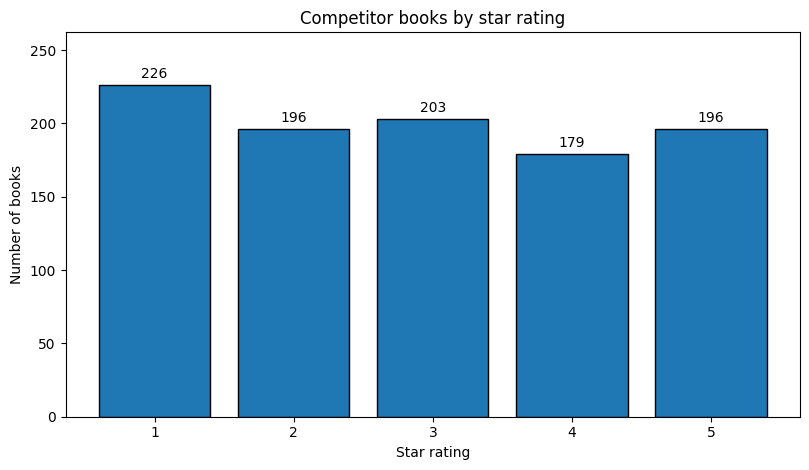


=== CEO £100 OPTIMAL BASKET ===
                                                                                   Title  Price  Rating
                                                  Old School (Diary of a Wimpy Kid #10)  11.83       5
                                                                   Greek Mythic History  10.23       5
                                                                     Dear Mr. Knightley  11.21       5
                                                                  The Origin of Species  10.01       4
Naturally Lean: 125 Nourishing Gluten-Free, Plant-Based Recipes--All Under 300 Calories  11.38       5
                             The Power Greens Cookbook: 140 Delicious Superfood Recipes  11.05       5
                                                                    The Darkest Corners  11.33       5
                                                             An Abundance of Katherines  10.00       5
                                       

<Figure size 640x480 with 0 Axes>

In [6]:
%run bookstore_scraper.py
